# 5장 2강: 학습 상태 진단과 Loss 분석 — 실습문제 풀이

> **풀이 기준**: 프로젝트에 업로드된 `concrete_data.csv`로 코드를 실제 실행한 결과입니다. 손실은 학습 데이터 기준으로 표준화한 목표의 MSE이며, MPa 단위나 정확도(%)가 아닙니다.
>
> **가정한 내용**
> - 문제 2-2의 B에 대한 개선 전략은 문제 지시대로 구현하지 않고 제안만 했습니다(Early Stopping을 선택).
> - 그래프 축 이름은 한글 글꼴 문제를 피하려고 영어로 표기했습니다.

---

## 공통 준비 코드 (제공 코드)

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_path = Path("concrete_data.csv")
if not data_path.exists():
    data_path = Path("concrete_data(1).csv")
original = pd.read_csv(data_path)
original.columns = original.columns.str.strip()
df = original.drop_duplicates().reset_index(drop=True)
target = "concrete_compressive_strength"
features = [name for name in df.columns if name != target]
indices = np.random.default_rng(42).permutation(len(df))
train_df = df.iloc[indices[:80]].copy()
valid_df = df.iloc[indices[80:280]].copy()

train_raw = train_df[features].to_numpy(dtype=float)
valid_raw = valid_df[features].to_numpy(dtype=float)
x_mean = train_raw.mean(axis=0)
x_std = train_raw.std(axis=0)
X_train = (train_raw - x_mean) / x_std
X_valid = (valid_raw - x_mean) / x_std
y_raw = train_df[[target]].to_numpy(dtype=float)
y_valid_raw = valid_df[[target]].to_numpy(dtype=float)
y_mean = y_raw.mean()
y_std = y_raw.std()
y_train = (y_raw - y_mean) / y_std
y_valid = (y_valid_raw - y_mean) / y_std

print("원본 / 중복 제거 후:", original.shape, df.shape)
print("결측값 수:", df.isna().sum().sum())
print("학습 / 검증 / 미사용 행:", len(train_df), len(valid_df), len(df)-280)
print("입력 / 목표 크기:", X_train.shape, y_train.shape)

원본 / 중복 제거 후: (1030, 9) (1005, 9)
결측값 수: 0
학습 / 검증 / 미사용 행: 80 200 725
입력 / 목표 크기: (80, 8) (80, 1)


In [2]:
def predict(values, params):
    w1, b1, w2, b2 = params
    return np.tanh(values @ w1 + b1) @ w2 + b2


def train_demo(lr=0.03, epochs=1200):
    rng = np.random.default_rng(7)
    w1 = rng.normal(0.0, 0.3, size=(8, 32))
    b1 = np.zeros((1, 32))
    w2 = rng.normal(0.0, 0.1, size=(32, 1))
    b2 = np.zeros((1, 1))
    records = []
    for epoch in range(1, epochs + 1):
        hidden = np.tanh(X_train @ w1 + b1)
        prediction = hidden @ w2 + b2
        grad_output = 2.0 * (prediction - y_train) / len(X_train)
        grad_w2 = hidden.T @ grad_output
        grad_b2 = grad_output.sum(axis=0, keepdims=True)
        grad_hidden = (grad_output @ w2.T) * (1.0 - hidden**2)
        grad_w1 = X_train.T @ grad_hidden
        grad_b1 = grad_hidden.sum(axis=0, keepdims=True)
        w1 -= lr * grad_w1
        b1 -= lr * grad_b1
        w2 -= lr * grad_w2
        b2 -= lr * grad_b2
        params = (w1, b1, w2, b2)
        train_loss = np.mean((predict(X_train, params) - y_train)**2)
        valid_loss = np.mean((predict(X_valid, params) - y_valid)**2)
        records.append({"epoch": epoch, "train_loss": train_loss,
                        "valid_loss": valid_loss})
        if not np.isfinite([train_loss, valid_loss]).all():
            print("유한하지 않은 손실이 발생해 기록을 중단했습니다:", epoch)
            break
    return pd.DataFrame(records)


def plot_pair(frame, ax, title, log_scale=False):
    ax.plot(frame["epoch"], frame["train_loss"], label="Train", color="#2563eb")
    ax.plot(frame["epoch"], frame["valid_loss"], label="Validation", color="#d97706")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE (standardized target)")
    if log_scale:
        ax.set_yscale("log")
    ax.grid(alpha=0.2)
    ax.legend()


print("학습·예측·그래프 함수 준비 완료")

학습·예측·그래프 함수 준비 완료


---

## 실습 1. Loss의 의미와 Learning Curve 읽기

### 문제 1-1. 학습 손실과 검증 손실은 어떻게 계산할까요?

In [3]:
train_pred = np.zeros_like(y_train)
valid_pred = np.zeros_like(y_valid)
baseline_train = np.mean((train_pred - y_train)**2)
baseline_valid = np.mean((valid_pred - y_valid)**2)
print("기준 모델 학습 MSE:", round(baseline_train, 6))
print("기준 모델 검증 MSE:", round(baseline_valid, 6))

first3 = pd.DataFrame({
    "actual": y_train[:3, 0],
    "prediction": train_pred[:3, 0],
})
first3["error"] = first3["prediction"] - first3["actual"]
first3["squared_error"] = first3["error"]**2
print(first3.round(6).to_string(index=False))
print("처음 3행 MSE:", round(first3["squared_error"].mean(), 6))

기준 모델 학습 MSE: 1.0
기준 모델 검증 MSE: 1.22032
   actual  prediction     error  squared_error
-1.393988         0.0  1.393988       1.943203
-1.401352         0.0  1.401352       1.963787
 1.240252         0.0 -1.240252       1.538224
처음 3행 MSE: 1.815071


#### 답변

**계산 과정 (처음 3행)**

- 오차: 0 − (−1.393988) = 1.393988, 0 − (−1.401352) = 1.401352, 0 − 1.240252 = −1.240252
- 제곱: 1.943203, 1.963787, 1.538224
- 평균: (1.943203 + 1.963787 + 1.538224) / 3 ≈ **1.815071**

**Q1. Training Loss와 Validation Loss는 어떤 데이터로 구하나요? 어떤 데이터가 가중치 업데이트에 직접 사용되나요?**

- Training Loss는 **학습 80행**, Validation Loss는 **검증 200행**에서 계산합니다.
- 가중치 업데이트(기울기 계산)에는 **학습 데이터만** 사용합니다. 검증 데이터는 상태 확인용입니다.

**Q2. 전체 학습 MSE와 검증 MSE는 각각 얼마인가요? 처음 3행의 MSE가 전체 학습 MSE와 다른 이유는 무엇인가요?**

- 학습 MSE **1.0**, 검증 MSE **1.220320**입니다.
- MSE는 평균이므로 어떤 행을 포함하느냐에 따라 달라집니다. 처음 3행은 모두 평균에서 많이 떨어진 값(|표준화값| > 1.2)이라 3행만의 MSE가 1.815071로 전체보다 큽니다.

**Q3. MSE 1.0은 정확도 100% 또는 1 MPa의 오차를 의미하나요? 왜 기준 모델의 학습 MSE가 1.0인가요?**

- 둘 다 아닙니다. 이 MSE는 **표준화된 목표값**의 평균 제곱 오차로, 정확도도 MPa 단위도 아닙니다(√1 × 14.94 ≈ 14.94 MPa 정도의 RMSE에 해당).
- 학습 목표는 학습 평균을 빼고 학습 표준편차로 나눴으므로 평균 0, 분산 1입니다. 모두 0으로 예측하면 MSE = mean(y²) = 분산 = **1**이 됩니다. 검증 데이터는 학습 기준으로 표준화했으므로 정확히 1이 아닙니다(1.22).

---

### 문제 1-2. 두 곡선의 변화와 검증 최저점 찾기

 epoch  train_loss  valid_loss
     1    1.309837    1.658692
     5    0.821426    1.070781
   100    0.221291    0.467928
   300    0.163064    0.408041
   600    0.122144    0.395813
  1200    0.084271    0.397232

검증 최저 행:
epoch         584.000000
train_loss      0.123617
valid_loss      0.395805
최저 이후 검증 손실 증가폭: 0.001428


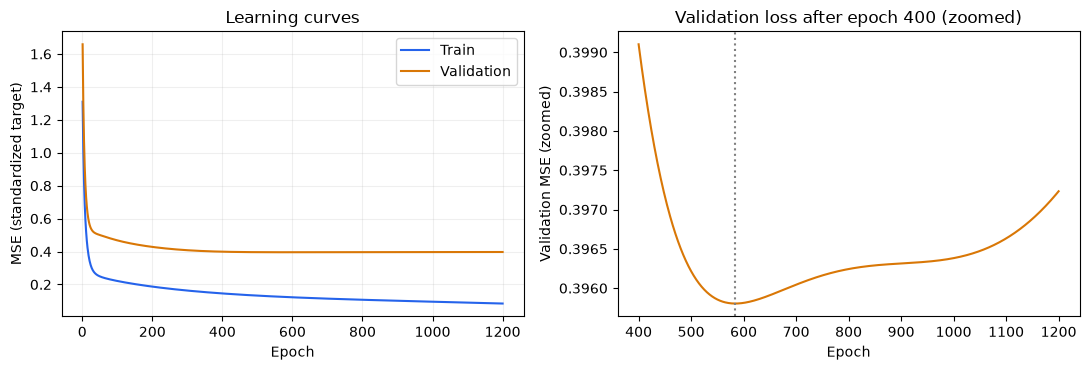

In [4]:
history = train_demo(lr=0.03, epochs=1200)
selected = history[history["epoch"].isin([1, 5, 100, 300, 600, 1200])]
print(selected.round(6).to_string(index=False))

best_row = history.loc[history["valid_loss"].idxmin()]
print("\n검증 최저 행:")
print(best_row.round(6).to_string())
last_row = history.iloc[-1]
print("최저 이후 검증 손실 증가폭:", round(last_row["valid_loss"] - best_row["valid_loss"], 6))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_pair(history, axes[0], "Learning curves")
late = history[history["epoch"] >= 400]
axes[1].plot(late["epoch"], late["valid_loss"], color="#d97706")
axes[1].axvline(best_row["epoch"], linestyle=":", color="gray")
axes[1].set_title("Validation loss after epoch 400 (zoomed)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation MSE (zoomed)")
fig.tight_layout()

#### 답변

**결과 정리**

- 검증 최저: **584 epoch**(학습 0.123617, 검증 0.395805)
- 마지막: 1200 epoch(학습 0.084271, 검증 0.397232)
- 최저 이후 검증 손실 증가폭: **0.001427**

**Q1. 초기 구간에서 두 손실이 함께 내려가는 것은 무엇을 의미하나요?**

- 1 → 5 → 100 epoch 동안 학습 1.31 → 0.82 → 0.22, 검증 1.66 → 1.07 → 0.47로 함께 줄었습니다. 모델이 학습 데이터에만 해당하는 것이 아니라 **새 데이터에도 통하는 일반적인 관계**를 배우고 있다는 뜻입니다.

**Q2. 검증 최저 시점과 마지막 시점의 두 손실을 비교해 어떤 징후를 설명할 수 있나요? 검증 손실의 악화 폭도 함께 말하세요.**

- 584 → 1200 epoch 동안 학습 손실은 0.1236 → 0.0843으로 계속 줄었지만, 검증 손실은 0.3958 → 0.3972로 **0.0014 늘었습니다**. 학습만 좋아지고 검증은 조금 나빠지는 **약한 과적합 징후**입니다. 악화 폭은 최저값 대비 약 0.36%로 작습니다.

**Q3. 검증 손실이 학습 손실보다 크다는 이유만으로 과적합을 확정할 수 있나요? 확대 그림을 해석할 때 무엇을 주의해야 하나요?**

- 확정할 수 없습니다. 1 epoch부터 검증 손실은 늘 학습 손실보다 컸지만, 584 epoch까지는 둘 다 함께 줄어든 정상 학습 구간이었습니다. 과적합은 차이 자체보다 **추세**(학습은 줄고 검증은 늘어남)로 판단합니다.
- 확대 그림은 세로축 범위가 약 0.3955~0.3995로 매우 좁아서 작은 변화도 크게 보입니다. 축 눈금을 확인하고, 실제 변화량(0.0014)을 숫자로 함께 봐야 과장하지 않습니다.

---

## 실습 2. 학습 상태 진단과 개선 전략

### 문제 2-1. 네 가지 기록에서 근거 찾기

case  first_epoch  last_epoch  first_train  last_train  first_valid  last_valid
   A            1           5      1.30984    0.821426      1.65869     1.07078
   B          400        1200     0.145534   0.0842713     0.399101    0.397232
   C            1         300      1.52081     1.49868      1.91447     1.88776
   D            1          12      3.29382 9.24529e+22       3.3659 6.85209e+22

D의 전체 기록:
 epoch  train_loss  valid_loss
     1     3.29382      3.3659
     2     3.06472     2.68971
     3     157.823     127.514
     4      9287.1     8246.61
     5      251003      176173
     6 8.09327e+06 7.51879e+06
     7 5.42082e+09 4.43143e+09
     8 3.68673e+12 3.02715e+12
     9 1.98997e+15   1.684e+15
    10 8.51891e+17 6.78494e+17
    11 3.07112e+20 2.48678e+20
    12 9.24529e+22 6.85209e+22


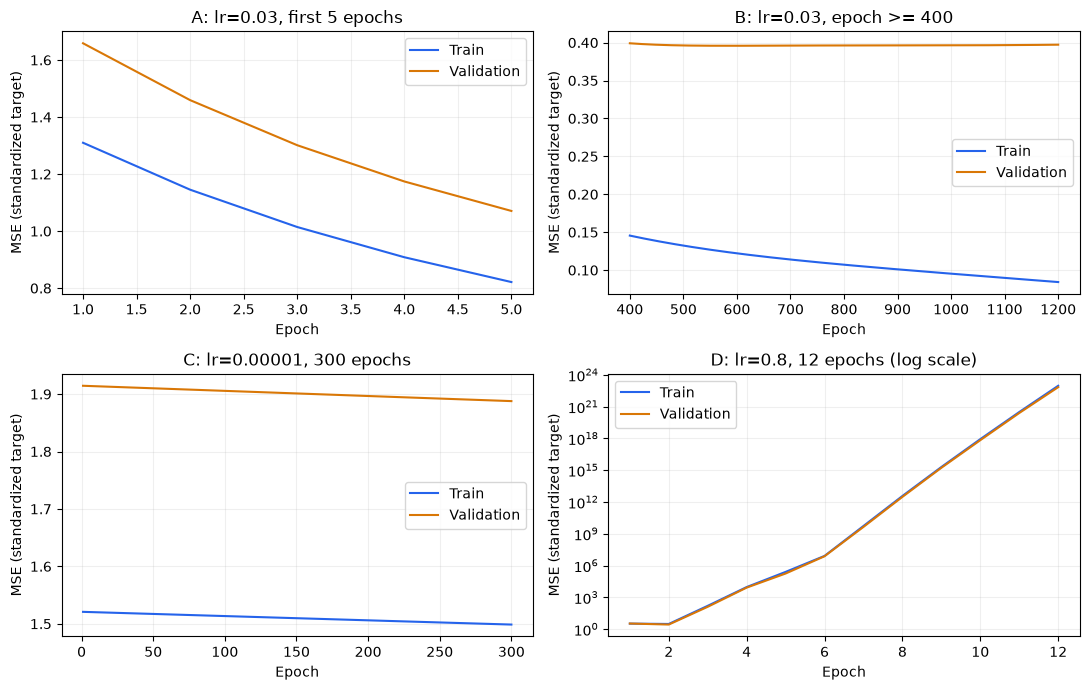

In [5]:
case_a = history[history["epoch"] <= 5].copy()
case_b = history[history["epoch"] >= 400].copy()
case_c = train_demo(lr=0.00001, epochs=300)
case_d = train_demo(lr=0.8, epochs=12)
cases = {"A": case_a, "B": case_b, "C": case_c, "D": case_d}

rows = []
for name, frame in cases.items():
    first, last = frame.iloc[0], frame.iloc[-1]
    rows.append({"case": name, "first_epoch": int(first["epoch"]), "last_epoch": int(last["epoch"]),
                 "first_train": first["train_loss"], "last_train": last["train_loss"],
                 "first_valid": first["valid_loss"], "last_valid": last["valid_loss"]})
summary = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
print(summary.to_string(index=False))
print()
print("D의 전체 기록:")
print(case_d.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
titles = {"A": "A: lr=0.03, first 5 epochs", "B": "B: lr=0.03, epoch >= 400",
          "C": "C: lr=0.00001, 300 epochs", "D": "D: lr=0.8, 12 epochs (log scale)"}
for ax, (name, frame) in zip(axes.flat, cases.items()):
    plot_pair(frame, ax, titles[name], log_scale=(name == "D"))
fig.tight_layout()

#### 답변

**사례별 정리**

| 사례 | 처음 → 마지막 학습 손실 | 처음 → 마지막 검증 손실 | 진단 |
|---|---|---|---|
| A | 1.309837 → 0.821426 | 1.658692 → 1.070781 | 학습 부족(과소적합) |
| B | 0.145534 → 0.084271 | 0.399101 → 0.397232 (584에서 최저 0.395805) | 약한 과적합 징후 |
| C | 1.520809 → 1.498685 | 1.914466 → 1.887762 | 학습 정체 + 과소적합 |
| D | 3.29 → 9.25 × 10²² | 3.37 → 6.85 × 10²² | 발산 |

**Q1. A를 이후 300 epoch의 결과와 비교하면 어떤 상태의 징후가 있나요? 모델이 너무 작다는 결론까지 낼 수 있나요?**

- 5 epoch 학습 0.821, 검증 1.071은 같은 설정으로 300 epoch까지 학습한 결과(학습 0.163, 검증 0.408)보다 훨씬 높습니다. 학습 데이터조차 충분히 맞추지 못한 **과소적합(학습 부족)** 상태입니다.
- 모델이 작다는 결론은 낼 수 없습니다. 같은 모델이 학습만 더 하면 손실이 크게 줄었으므로, 원인은 모델 크기가 아니라 **학습 횟수 부족**입니다.

**Q2. B에는 어떤 징후가 있나요? 어느 두 손실의 변화가 근거인가요?**

- **약한 과적합 징후**입니다. 400 → 1200 epoch 동안 학습 손실은 0.1455 → 0.0843으로 계속 줄었지만, 검증 손실은 584 epoch에서 0.395805로 최저를 찍은 뒤 1200 epoch에 0.397232로 소폭 늘었습니다. 학습 손실 감소와 검증 손실의 정체·소폭 증가가 근거입니다.

**Q3. C는 완전히 학습이 멈춘 것인가요? 이번 설정에서 우선 확인할 원인은 무엇인가요?**

- 완전히 멈추지는 않았습니다. 300 epoch 동안 학습 손실이 1.5208 → 1.4987로 **아주 조금씩** 줄고 있습니다. 개선이 매우 느린 **학습 정체**이며, 손실이 기준 모델(1.0)보다도 높아 **과소적합**이기도 합니다.
- 우선 확인할 원인은 **너무 작은 학습률(0.00001)**입니다. 기울기를 아주 조금만 반영해 가중치가 거의 바뀌지 않습니다.

**Q4. D를 검증 손실만 나빠지는 과적합과 어떻게 구별하나요? 반드시 NaN이 나와야 발산을 의심할 수 있나요?**

- 과적합은 학습 손실은 줄고 검증 손실만 나빠지지만, D는 **학습 손실과 검증 손실이 함께** 3 epoch부터 수십~수백 배씩 폭증합니다(3.06 → 157.8 → 9,287 → … → 9.2 × 10²²). 학습 데이터에서조차 손실이 커지므로 과적합이 아닌 **발산**입니다.
- 아닙니다. NaN은 발산이 더 진행된 결과일 뿐입니다. 이번에도 NaN 없이 유한한 값이었지만, 손실이 반복적으로 급증하는 추세만으로 충분히 발산을 의심할 수 있습니다.

**Q5. 과소적합·학습 정체를 동시에 말할 수 있나요? 낮은 손실에서 두 곡선이 평평해졌을 때도 반드시 문제인가요?**

- 동시에 말할 수 있습니다. C처럼 **높은 손실에서** 개선이 거의 없으면 정체이면서 과소적합입니다.
- 반드시 문제는 아닙니다. 두 손실이 **충분히 낮은 수준에서** 평평해졌고 검증 손실도 나빠지지 않는다면, 학습이 잘 된 뒤 안정된 정상적인 **수렴**일 수 있습니다.

---

### 문제 2-2. 설정 하나를 바꾸고 개선 방향 확인하기

In [6]:
def at_epoch(frame, epoch):
    return frame.loc[frame["epoch"] == epoch].iloc[0]

comparisons = [
    ("A", "학습 횟수 5 → 300 (lr 0.03 유지)", at_epoch(history, 5), at_epoch(history, 300)),
    ("C", "학습률 0.00001 → 0.03 (300 epoch 유지)", at_epoch(case_c, 300), at_epoch(history, 300)),
    ("D", "학습률 0.8 → 0.03 (12 epoch 유지)", at_epoch(case_d, 12), at_epoch(history, 12)),
]
rows = []
for name, change, before, after in comparisons:
    rows.append({"case": name, "change": change,
                 "train_before": before["train_loss"], "train_after": after["train_loss"],
                 "valid_before": before["valid_loss"], "valid_after": after["valid_loss"]})
print(pd.DataFrame(rows).to_string(index=False))

case                            change  train_before  train_after  valid_before  valid_after
   A        학습 횟수 5 → 300 (lr 0.03 유지)      0.821426     0.163064       1.07078     0.408041
   C 학습률 0.00001 → 0.03 (300 epoch 유지)       1.49868     0.163064       1.88776     0.408041
   D      학습률 0.8 → 0.03 (12 epoch 유지)   9.24529e+22     0.491047   6.85209e+22      0.70019


#### 답변

**Q1. A·C·D는 각각 무엇을 바꾸었고 두 손실은 어느 방향으로 변했나요?**

| 사례 | 바꾼 설정 | 학습 손실 | 검증 손실 |
|---|---|---|---|
| A | 학습 횟수 5 → 300 | 0.821426 → 0.163064 (감소) | 1.070781 → 0.408041 (감소) |
| C | 학습률 0.00001 → 0.03 | 1.498685 → 0.163064 (감소) | 1.887762 → 0.408041 (감소) |
| D | 학습률 0.8 → 0.03 | 9.25 × 10²² → 0.491047 (감소) | 6.85 × 10²² → 0.700190 (감소) |

- 세 경우 모두 진단에 맞게 설정을 바꾸자 두 손실이 함께 크게 줄었습니다. A는 학습 횟수를 늘리고, C는 학습률을 높이고, D는 학습률을 낮춘 것이 효과가 있었습니다.

**Q2. B에 맞는 개선 전략은 무엇인가요? Dropout·Weight Decay를 강하게 적용하거나 Batch Normalization을 넣으면 언제나 해결되나요?**

- 제안 전략: **Early Stopping**으로 검증 손실이 가장 낮았던 584 epoch 근처에서 학습을 멈추고 그 가중치를 복원합니다. 학습 데이터가 80행으로 적으므로, 적당한 Dropout이나 Weight Decay를 추가해 같은 조건에서 검증 손실을 비교해 보는 것도 방법입니다.
- 언제나 해결되지 않습니다. 너무 강한 Dropout·Weight Decay는 학습 자체를 방해해 **과소적합**을 만들 수 있고, BN은 주로 학습 안정화 기법이라 과적합 해결을 보장하지 않습니다. 이번 B의 악화 폭(0.0014)은 매우 작아서, 강한 규제보다는 중단 시점 선택이 먼저입니다.

**Q3. 비교할 때 다른 조건을 같게 유지하는 이유는 무엇인가요? 학습률 0.03이 모든 문제의 정답인가요?**

- 여러 조건을 한꺼번에 바꾸면 손실 변화가 어느 설정 때문인지 알 수 없습니다. 데이터·초기값·모델·비교 시점을 고정하고 **한 가지만 바꿔야** 그 설정의 효과로 해석할 수 있습니다.
- 정답이 아닙니다. 이번 데이터·모델·초기값에서 잘 동작한 값일 뿐이며, 데이터와 모델이 바뀌면 알맞은 학습률도 달라집니다.

---

## 기초 과제. 근거를 붙여 학습 결과 선택하기

### 문제 3-1. 가장 작은 격차가 가장 좋은 결과일까요?

In [7]:
candidates = history[history["epoch"].isin([100, 584, 1200])].copy()
candidates["gap"] = candidates["valid_loss"] - candidates["train_loss"]
train_choice = candidates.loc[candidates["train_loss"].idxmin(), "epoch"]
valid_choice = candidates.loc[candidates["valid_loss"].idxmin(), "epoch"]
gap_choice = candidates.loc[candidates["gap"].idxmin(), "epoch"]
pd.set_option("display.float_format", lambda v: f"{v:.6f}")
print(candidates.to_string(index=False))
print("학습 손실 최소:", int(train_choice), "epoch")
print("검증 손실 최소:", int(valid_choice), "epoch")
print("gap 최소     :", int(gap_choice), "epoch")

 epoch  train_loss  valid_loss      gap
   100    0.221291    0.467928 0.246638
   584    0.123617    0.395805 0.272187
  1200    0.084271    0.397232 0.312961
학습 손실 최소: 1200 epoch
검증 손실 최소: 584 epoch
gap 최소     : 100 epoch


#### 답변

**후보 비교**

| epoch | 학습 손실 | 검증 손실 | gap |
|---:|---:|---:|---:|
| 100 | 0.221291 | 0.467928 | **0.246638** |
| 584 | 0.123617 | **0.395805** | 0.272187 |
| 1200 | **0.084271** | 0.397232 | 0.312961 |

**선택**: 검증 손실이 가장 낮은 **584 epoch**를 선택합니다. 새 데이터에 대한 성능을 가장 잘 대신하는 지표는 검증 손실이고, 584 epoch는 학습 손실도 100 epoch보다 낮아 학습이 충분히 진행된 상태입니다. 1200 epoch는 학습 손실이 더 낮지만 검증 손실이 오히려 조금 높습니다.

**Q1. 학습 손실·검증 손실·gap이 각각 가장 작은 후보는 몇 epoch인가요? 검증 기준으로 무엇을 선택하나요?**

- 학습 손실 최소 **1200**, 검증 손실 최소 **584**, gap 최소 **100**입니다.
- 검증 기준으로 **584 epoch**를 선택합니다.

**Q2. gap이 가장 작다는 이유만으로 가장 좋은 모델이라고 말할 수 없는 이유는 무엇인가요?**

- gap은 두 손실의 **차이**일 뿐, 손실의 **크기**를 알려 주지 않습니다. 100 epoch는 gap이 가장 작지만, 학습·검증 손실이 모두 584 epoch보다 높습니다. 즉 아직 덜 학습된 상태라 차이가 작은 것입니다. 극단적으로 둘 다 매우 높은 과소적합 모델도 gap은 작을 수 있습니다.

**Q3. 선택한 검증 최저값을 새로운 데이터에서 보장되는 성능이라고 발표해도 되나요?**

- 안 됩니다. 584 epoch는 검증 손실이 가장 낮은 시점이라 선택했지만, 바로 그 검증 데이터로 시점을 골랐으므로 0.395805는 실제보다 낙관적일 수 있습니다. 또 이 값은 표준화된 목표의 MSE이며, 학습 80행·검증 200행이라는 작은 표본의 결과입니다. 새 데이터에서의 성능은 따로 남겨 둔 테스트 데이터로 확인해야 합니다.

---

## 실습 마무리

**마무리 Q1. 표준화된 예측값 0이 실제로 무엇을 예측한다는 뜻인지 설명하세요. 기준 모델의 전체 학습 MSE, 검증 MSE, 처음 세 행 MSE와 서로 다른 이유를 쓰세요.**

- 표준화된 0은 **학습 데이터의 평균 압축강도(약 38.10 MPa)**를 모든 샘플에 똑같이 예측한다는 뜻입니다.
- 학습 MSE **1.0**, 검증 MSE **1.220320**, 처음 세 행 MSE **1.815071**입니다.
- 학습 목표는 학습 기준으로 표준화되어 분산이 정확히 1이고, 검증 데이터는 다른 샘플이라 분산이 1과 다릅니다. 처음 세 행은 평균에서 멀리 떨어진 값들이라 MSE가 더 큽니다.

**마무리 Q2. 584와 1200 epoch의 학습·검증 손실을 비교하여 상태를 설명하세요. 확대 그림의 기울기만 보고 악화를 판단하면 안 되는 이유는 무엇인가요?**

- 584 → 1200 epoch: 학습 0.123617 → 0.084271(감소), 검증 0.395805 → 0.397232(소폭 증가). 학습 데이터에만 더 맞춰지는 약한 과적합 징후입니다.
- 확대 그림은 세로축 범위가 매우 좁아 0.0014의 작은 증가도 가파르게 보입니다. 실제 변화량을 숫자로 확인해야 과장하지 않습니다.

**마무리 Q3. A·B·C·D의 상태를 각각 수치 또는 추세와 연결하세요. C가 완전히 멈춘 것인지, D는 NaN이 없어도 문제가 있는지 설명하세요.**

- A(과소적합): 5 epoch 학습 0.821, 검증 1.071로 300 epoch(0.163, 0.408)보다 훨씬 높음
- B(약한 과적합): 학습은 계속 감소, 검증은 584 epoch 최저 0.3958 이후 0.3972로 소폭 증가
- C(정체 + 과소적합): 300 epoch 동안 학습 1.5208 → 1.4987로 거의 그대로
- D(발산): 두 손실이 함께 급증해 12 epoch에 약 10²²
- C는 완전히 멈추지 않고 매우 느리게 줄고 있습니다. D는 NaN이 없어도 손실이 반복 급증하므로 분명한 문제(발산)입니다.

**마무리 Q4. A·C·D에서는 각각 어떤 설정을 바꾸어 확인했나요? C와 D를 모두 기준 모델의 1200 epoch와 비교하면 어떤 문제가 있나요?**

- A: 학습 횟수(5 → 300), C: 학습률(0.00001 → 0.03, 300 epoch), D: 학습률(0.8 → 0.03, 12 epoch)
- 1200 epoch와 비교하면 **학습률과 학습 횟수가 동시에** 달라집니다. 손실 차이가 학습률 때문인지 학습 횟수 때문인지 구분할 수 없으므로, 같은 epoch 시점(300, 12)과 비교해야 합니다.

**마무리 Q5. 학습 손실·검증 손실·gap 기준의 세 후보 선택 결과를 쓰세요. gap이 작다는 것이 검증 성능이 좋다는 뜻은 아닌 이유를 설명하세요.**

- 학습 손실 최소 1200, 검증 손실 최소 584, gap 최소 100 → 검증 기준으로 **584 epoch** 선택
- gap은 두 손실의 차이일 뿐입니다. 100 epoch는 gap이 가장 작지만 검증 손실(0.4679)이 584 epoch(0.3958)보다 높습니다. 차이가 작다는 것과 오차가 작다는 것은 다릅니다.

**마무리 Q6. 실제로 실행해 확인한 내용과 개선 전략으로만 제안한 내용을 구분하세요. 검증 최저 행을 골랐으면 최적 가중치 복원과 최종 테스트 평가도 끝난 것인가요?**

- 실행해 확인: 기준 모델 MSE, 학습률 0.03의 1200 epoch 곡선과 검증 최저점, A·B·C·D 진단, 학습 횟수·학습률을 하나씩 바꾼 비교, 후보 선택
- 제안만 함: B에 대한 Early Stopping과 Dropout·Weight Decay 적용(구현·검증하지 않음)
- 끝나지 않았습니다. `history`에는 손실 숫자만 있고 가중치(체크포인트)가 없으므로 584 epoch 모델을 복원하지 않았습니다. 테스트 데이터 평가도 하지 않았습니다.